# EDA: gold vs extracted data
Wheat fertilizer trial records extracted by the LLM (89 per-paper JSON files) compared with the gold standard (`gold_v3.xlsx`).

| Section | Content |
|---|---|
| A | Load the data and select the columns |
| B | Filter (yield, wheat) and harmonize (region, soil, coordinates) |
| C | Profiling: NA counts, summary statistics, categories |
| D | Fertilizer products to elemental N, P, K, S |
| E | Location: fill region/zone/woreda, remove unlocated records, filtering summary |
| F | Exploration: correlation, N and P vs yield, map, yield distribution |
| G | Human-annotated vs model-extracted: usable observations per paper and region |
| H | Final column selection |

## Section A. Load the data and select the columns
Load extracted (89 per-paper JSONs) and gold (`gold_v3.xlsx`, restricted to the 89 papers in `89_papers_gold.json`), add a common paper key, select the columns, convert to numeric, derive decimal coordinates.

In [ ]:
import json
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import difflib
import re

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# Full path to the project folder (falls back to the current folder if it does not exist)
BASE = Path('/Volumes/Data/01UM6P/AI_Papers/proposal/Proposal_versions/Chapters/Chapter1/data_extraction_md/script/downstream_fert_recom')
if not BASE.exists():
    BASE = Path('.')

EXT_DIR = BASE / 'mistral-small3.1-24b-instruct-2503-q4_K_M__text_only__zero_shot__all'
GOLD_XLSX = BASE / 'gold_v3.xlsx'
SPLITS_JSON = BASE / '89_papers_gold.json'

for p in [EXT_DIR, GOLD_XLSX, SPLITS_JSON]:
    print(('OK      ' if p.exists() else 'MISSING ') + str(p))

# pd.read_excel needs openpyxl: install it into this kernel if it is missing
try:
    import openpyxl
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'openpyxl'])
    import openpyxl

# Figure colours: extracted = M1 (orange), gold = M2 (green)
colors = {'extracted': '#dca237', 'gold': '#469c76'}

# Labels of the two datasets in the figures
dataset_labels = {'gold': 'Human-annotated', 'extracted': 'Model-extracted'}

OK      /Volumes/Data/01UM6P/AI_Papers/proposal/Proposal_versions/Chapters/Chapter1/data_extraction_md/script/downstream_fert_recom/mistral-small3.1-24b-instruct-2503-q4_K_M__text_only__zero_shot__all
OK      /Volumes/Data/01UM6P/AI_Papers/proposal/Proposal_versions/Chapters/Chapter1/data_extraction_md/script/downstream_fert_recom/gold_v3.xlsx
OK      /Volumes/Data/01UM6P/AI_Papers/proposal/Proposal_versions/Chapters/Chapter1/data_extraction_md/script/downstream_fert_recom/89_papers_gold.json


### A1. Extracted data: read the 89 JSON files and merge their `records`

In [2]:
ext_files = sorted(EXT_DIR.glob('*_zero_shot__text__*.json'))
print('JSON files found:', len(ext_files))
assert len(ext_files) == 89

ext_list = []
for path in ext_files:
    with open(path, encoding='utf-8') as f:
        data = json.load(f)
    df_tmp = pd.DataFrame(data['records'])
    # paper key taken from the file name (the model-written file_name / paper_doi columns are not reliable)
    df_tmp['paper_key'] = path.stem.split('__text__')[1]
    ext_list.append(df_tmp)

ext = pd.concat(ext_list, ignore_index=True, sort=False)
ext['dataset'] = 'extracted'
print('Extracted:', ext.shape, '| papers:', ext['paper_key'].nunique())

JSON files found: 89
Extracted: (1536, 72) | papers: 89


### A2. Gold data: `gold_v3.xlsx` restricted to the 89 papers listed in `89_papers_gold.json` (key `all`)
`89_papers_gold.json` holds the paper list and splits, not the records, so the records come from the workbook.

In [3]:
with open(SPLITS_JSON, encoding='utf-8') as f:
    papers_89 = json.load(f)['all']

gold = pd.read_excel(GOLD_XLSX, engine='openpyxl')
print('Workbook:', gold.shape, '| papers:', gold['file_name'].nunique())

gold = gold[gold['file_name'].isin(papers_89)].copy()
print('Gold (89 papers):', gold.shape, '| papers:', gold['file_name'].nunique())
assert gold['file_name'].nunique() == 89

Workbook: (2267, 106) | papers: 99
Gold (89 papers): (1711, 106) | papers: 89


### A3. Common paper key for gold (same rule as the JSON file names: DOI if available, otherwise file name)

In [4]:
doi = gold['paper_doi'].fillna('').astype(str).str.replace('doi:', '', regex=False).str.strip()
has_doi = (doi != '') & (doi.str.lower() != 'nan')

doi_key = 'doi_' + doi.str.replace(r'[^0-9A-Za-z]+', '_', regex=True).str.strip('_')
file_key = 'file_' + gold['file_name'].astype(str).str.replace(r'[^0-9A-Za-z]+', '_', regex=True).str.strip('_')

gold['paper_key'] = np.where(has_doi, doi_key, file_key)
gold['dataset'] = 'gold'

print('Same 89 papers in both datasets:', set(gold['paper_key']) == set(ext['paper_key']))

Same 89 papers in both datasets: True


### A4. Select the required columns
Columns missing in a dataset are added as NaN (and listed).

In [5]:
cols = ['file_name',
        'region', 'zone', 'woreda', 'site_name',
        'lat_degree', 'lat_minute', 'lat_second', 'lat_decimal',
        'long_degree', 'long_minute', 'long_second', 'long_decimal',
        'trial_year', 'altitude', 'total_rainfall', 'mean_tmax', 'mean_tmin',
        'soil_type', 'sand_pct', 'silt_pct', 'clay_pct', 'ph', 'cec', 'soc', 'total_n',
        'crop', 'variety',
        'n_rate', 'p_rate', 'k_rate', 's_rate', 'p2o5', 'k2o', 'urea', 'dap', 'tsp', 'kcl',
        'nps', 'npsb', 'npszn', 'npsznb',
        'grain_yield']
id_cols = ['dataset', 'paper_key']

print('Missing in extracted:', [c for c in cols if c not in ext.columns])
print('Missing in gold     :', [c for c in cols if c not in gold.columns])

for c in cols:
    if c not in ext.columns:
        ext[c] = np.nan
    if c not in gold.columns:
        gold[c] = np.nan

ext = ext[id_cols + cols].copy()
gold = gold[id_cols + cols].copy()
print('Extracted:', ext.shape, '| Gold:', gold.shape)

Missing in extracted: []
Missing in gold     : ['lat_decimal', 'long_decimal']
Extracted: (1536, 45) | Gold: (1711, 45)


### A5. Convert numeric columns to numbers

In [6]:
text_cols = ['file_name', 'trial_year', 'region', 'zone', 'woreda', 'site_name', 'soil_type', 'crop', 'variety']
num_cols = [c for c in cols if c not in text_cols]

for name, df in [('extracted', ext), ('gold', gold)]:
    for c in num_cols:
        n_before = df[c].notna().sum()
        df[c] = pd.to_numeric(df[c], errors='coerce')
        n_after = df[c].notna().sum()
        if n_before != n_after:
            print(f'{name}: {c}: {n_before - n_after} non-numeric values became NaN')
print('done')

done


### A6. Decimal coordinates
Fill missing `lat_decimal` / `long_decimal` from degree + minute/60 + second/3600 (all coordinates are north / east in Ethiopia), then flag values outside Ethiopia (lat 3-15, long 33-48). Flagged values are reported, not changed.

In [7]:
for name, df in [('extracted', ext), ('gold', gold)]:
    n_lat_before = df['lat_decimal'].notna().sum()
    n_long_before = df['long_decimal'].notna().sum()

    lat_calc = df['lat_degree'] + df['lat_minute'].fillna(0) / 60 + df['lat_second'].fillna(0) / 3600
    long_calc = df['long_degree'] + df['long_minute'].fillna(0) / 60 + df['long_second'].fillna(0) / 3600
    df['lat_decimal'] = df['lat_decimal'].fillna(lat_calc)
    df['long_decimal'] = df['long_decimal'].fillna(long_calc)

    lat_out = df['lat_decimal'].notna() & ~df['lat_decimal'].between(3, 15)
    long_out = df['long_decimal'].notna() & ~df['long_decimal'].between(33, 48)
    print(f"{name}: lat_decimal {n_lat_before} -> {df['lat_decimal'].notna().sum()}, "
          f"long_decimal {n_long_before} -> {df['long_decimal'].notna().sum()} | "
          f"outside Ethiopia: lat {lat_out.sum()}, long {long_out.sum()}")

extracted: lat_decimal 1266 -> 1266, long_decimal 1280 -> 1280 | outside Ethiopia: lat 65, long 78
gold: lat_decimal 0 -> 1659, long_decimal 0 -> 1659 | outside Ethiopia: lat 39, long 24


### A7. Check

In [8]:
print('Extracted:', ext.shape, '| papers:', ext['paper_key'].nunique())
print('Gold     :', gold.shape, '| papers:', gold['paper_key'].nunique())
ext.head()

Extracted: (1536, 45) | papers: 89
Gold     : (1711, 45) | papers: 89


,dataset,paper_key,file_name,region,zone,woreda,site_name,lat_degree,lat_minute,lat_second,lat_decimal,long_degree,long_minute,long_second,long_decimal,trial_year,altitude,total_rainfall,mean_tmax,mean_tmin,soil_type,sand_pct,silt_pct,clay_pct,ph,cec,soc,total_n,crop,variety,n_rate,p_rate,k_rate,s_rate,p2o5,k2o,urea,dap,tsp,kcl,nps,npsb,npszn,npsznb,grain_yield
0,extracted,doi_10_1002_agg2_70248,None,None,North Wollo,Wadla,None,11.0,49.0,59.99,11.833331,38.0,49.0,59.99,38.833331,2023,2000.0,NaN,22.2,13.5,Nitisols,40.0,27.5,32.5,5.94,22.48,1.68,0.18,_Triticum aestivum_ L.,Denda’a,0.0,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1493.4
1,extracted,doi_10_1002_agg2_70248,None,None,North Wollo,Wadla,None,11.0,49.0,59.99,11.833331,38.0,49.0,59.99,38.833331,2023,2000.0,NaN,22.2,13.5,Nitisols,40.0,27.5,32.5,5.94,22.48,1.68,0.18,_Triticum aestivum_ L.,Denda’a,46.0,10.0372,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2260.0
2,extracted,doi_10_1002_agg2_70248,None,None,North Wollo,Wadla,None,11.0,49.0,59.99,11.833331,38.0,49.0,59.99,38.833331,2023,2000.0,NaN,22.2,13.5,Nitisols,40.0,27.5,32.5,5.94,22.48,1.68,0.18,_Triticum aestivum_ L.,Denda’a,46.0,20.0744,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2598.3
3,extracted,doi_10_1002_agg2_70248,None,None,North Wollo,Wadla,None,11.0,49.0,59.99,11.833331,38.0,49.0,59.99,38.833331,2023,2000.0,NaN,22.2,13.5,Nitisols,40.0,27.5,32.5,5.94,22.48,1.68,0.18,_Triticum aestivum_ L.,Denda’a,46.0,30.1116,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2833.7
4,extracted,doi_10_1002_agg2_70248,None,None,North Wollo,Wadla,None,11.0,49.0,59.99,11.833331,38.0,49.0,59.99,38.833331,2023,2000.0,NaN,22.2,13.5,Nitisols,40.0,27.5,32.5,5.94,22.48,1.68,0.18,_Triticum aestivum_ L.,Denda’a,46.0,40.1488,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2861.8


In [9]:
gold.head()

,dataset,paper_key,file_name,region,zone,woreda,site_name,lat_degree,lat_minute,lat_second,lat_decimal,long_degree,long_minute,long_second,long_decimal,trial_year,altitude,total_rainfall,mean_tmax,mean_tmin,soil_type,sand_pct,silt_pct,clay_pct,ph,cec,soc,total_n,crop,variety,n_rate,p_rate,k_rate,s_rate,p2o5,k2o,urea,dap,tsp,kcl,nps,npsb,npszn,npsznb,grain_yield
0,gold,doi_10_1080_23311843_2020_1778996,google_scholar (43),Tigray,Eastern,Hawzien,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015,NaN,NaN,NaN,NaN,Cambisols,71.0,13.0,16.0,6.2,19.4,0.8,0.082,Wheat,Kakaba,0.0,NaN,NaN,30.0,46.0,NaN,NaN,NaN,NaN,100.0,NaN,NaN,NaN,NaN,1102.73
1,gold,doi_10_1080_23311843_2020_1778996,google_scholar (43),Tigray,Eastern,Hawzien,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015,NaN,NaN,NaN,NaN,Cambisols,71.0,13.0,16.0,6.2,19.4,0.8,0.082,Wheat,Kakaba,32.0,NaN,NaN,30.0,46.0,NaN,NaN,NaN,NaN,100.0,NaN,NaN,NaN,NaN,1393.22
2,gold,doi_10_1080_23311843_2020_1778996,google_scholar (43),Tigray,Eastern,Hawzien,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015,NaN,NaN,NaN,NaN,Cambisols,71.0,13.0,16.0,6.2,19.4,0.8,0.082,Wheat,Kakaba,64.0,NaN,NaN,30.0,46.0,NaN,NaN,NaN,NaN,100.0,NaN,NaN,NaN,NaN,1708.33
3,gold,doi_10_1080_23311843_2020_1778996,google_scholar (43),Tigray,Eastern,Hawzien,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015,NaN,NaN,NaN,NaN,Cambisols,71.0,13.0,16.0,6.2,19.4,0.8,0.082,Wheat,Kakaba,96.0,NaN,NaN,30.0,46.0,NaN,NaN,NaN,NaN,100.0,NaN,NaN,NaN,NaN,1633.91
4,gold,doi_10_1080_23311843_2020_1778996,google_scholar (43),Tigray,Eastern,Hawzien,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015,NaN,NaN,NaN,NaN,Cambisols,71.0,13.0,16.0,6.2,19.4,0.8,0.082,Wheat,Kakaba,64.0,NaN,NaN,30.0,46.0,NaN,NaN,NaN,NaN,100.0,NaN,NaN,NaN,NaN,1543.19


## Section B. Filter and harmonize
Valid `grain_yield` filter, wheat filter, region and soil harmonization and the coordinate check.

### B1. Keep valid `grain_yield` only
Remove rows where `grain_yield` is NaN, below 100 or above 10,000 kg/ha (both datasets).

In [10]:
filter_log = []      # rows kept after each filter (summarised in E5)

# Extracted
n_all = len(ext)
n_na = ext['grain_yield'].isna().sum()
n_low = (ext['grain_yield'] < 100).sum()
n_high = (ext['grain_yield'] > 10000).sum()
ext = ext[ext['grain_yield'].between(100, 10000)].copy()
filter_log.append({'step': 'grain_yield 100-10000', 'dataset': 'extracted', 'rows_before': n_all, 'rows_after': len(ext)})
print(f'Extracted: {n_all} -> {len(ext)} rows | NaN: {n_na}, < 100: {n_low}, > 10000: {n_high}')

# Gold
n_all = len(gold)
n_na = gold['grain_yield'].isna().sum()
n_low = (gold['grain_yield'] < 100).sum()
n_high = (gold['grain_yield'] > 10000).sum()
gold = gold[gold['grain_yield'].between(100, 10000)].copy()
filter_log.append({'step': 'grain_yield 100-10000', 'dataset': 'gold', 'rows_before': n_all, 'rows_after': len(gold)})
print(f'Gold     : {n_all} -> {len(gold)} rows | NaN: {n_na}, < 100: {n_low}, > 10000: {n_high}')

Extracted: 1536 -> 1463 rows | NaN: 55, < 100: 12, > 10000: 6
Gold     : 1711 -> 1709 rows | NaN: 0, < 100: 0, > 10000: 2


### B2. Keep wheat records (bread wheat, durum wheat, wheat)
Crop names are folded to `Bread wheat`, `Durum wheat` or `Wheat`. Records with no crop value are kept.

In [11]:
crop_map = {}
for raw in pd.concat([ext['crop'], gold['crop']]).dropna().unique():
    s = str(raw).lower()
    is_wheat = ('wheat' in s) or ('trit' in s)          # 'trit' also catches the misspelling 'Tritcum'
    other = any(k in s for k in ['tef', 'maize', 'barley', 'bean', 'potato', 'sorghum', 'chickpea'])
    if is_wheat and not other:
        if 'durum' in s or 'turgidum' in s:
            crop_map[raw] = 'Durum wheat'
        elif 'bread' in s or 'aestivum' in s:
            crop_map[raw] = 'Bread wheat'
        else:
            crop_map[raw] = 'Wheat'
    else:
        crop_map[raw] = None                            # not wheat, or a mix of crops

# Extracted
crop_new = ext['crop'].map(crop_map)
print(f'Extracted: {len(ext)} rows | no crop (kept): {ext["crop"].isna().sum()}, other/mixed crop (removed): {(ext["crop"].notna() & crop_new.isna()).sum()}')
keep_ext = ext['crop'].isna() | crop_new.notna()      # rows with no crop are kept in the extracted data
n_before = len(ext)
ext['crop'] = crop_new
ext = ext[keep_ext].copy()
filter_log.append({'step': 'wheat only (no-crop rows kept)', 'dataset': 'extracted', 'rows_before': n_before, 'rows_after': len(ext)})

# Gold
crop_new = gold['crop'].map(crop_map)
print(f'Gold     : {len(gold)} rows | no crop (kept): {gold["crop"].isna().sum()}, other/mixed crop (removed): {(gold["crop"].notna() & crop_new.isna()).sum()}')
keep_gold = gold['crop'].isna() | crop_new.notna()    # rows with no crop are kept, as in the extracted data
n_before = len(gold)
gold['crop'] = crop_new
gold = gold[keep_gold].copy()
filter_log.append({'step': 'wheat only (no-crop rows kept)', 'dataset': 'gold', 'rows_before': n_before, 'rows_after': len(gold)})

print('After the wheat filter -> extracted:', len(ext), '| gold:', len(gold))
print(ext['crop'].value_counts().to_dict(), gold['crop'].value_counts().to_dict())

Extracted: 1463 rows | no crop (kept): 116, other/mixed crop (removed): 63
Gold     : 1709 rows | no crop (kept): 3, other/mixed crop (removed): 67
After the wheat filter -> extracted: 1400 | gold: 1642
{'Bread wheat': 636, 'Wheat': 525, 'Durum wheat': 123} {'Wheat': 1095, 'Bread wheat': 467, 'Durum wheat': 77}


### B3. Harmonize region names and soil types
Same rules as the extraction harness (`wheat_extraction_v23.ipynb`, step 9b): region names are folded to the gold spellings (e.g. all long forms of SNNP -> `SNNP`), and soil types to WRB reference-group names (e.g. `Nitosol`, `nitisol` -> `Nitisols`). Soil values that contain no WRB group name (e.g. texture classes such as `Clay`) are left unchanged and listed.

In [ ]:

# ---- Region ----
REGION_MAP = {
    'addis ababa': 'Addis Ababa', 'afar': 'Afar', 'amara': 'Amhara', 'amhara': 'Amhara',
    'benishangul gumuz': 'Benishangul-Gumuz', 'benishangul-gumuz': 'Benishangul-Gumuz',
    'central eth': 'Central Ethiopia', 'central ethiopia': 'Central Ethiopia',
    'dire dawa': 'Dire Dawa', 'gambella': 'Gambella', 'harari': 'Harari',
    'orom ia': 'Oromia', 'oromia': 'Oromia', 'oromio': 'Oromia', 'oromiya': 'Oromia',
    'sidama': 'Sidama', 'snnp': 'SNNP', 'snnpr': 'SNNP', 'snnprs': 'SNNP', 'somali': 'Somali',
    'south eth': 'SNNP', 'south ethiopia': 'SNNP', 'south-ethiopia': 'SNNP',
    'southern eth': 'SNNP', 'southern ethiopia': 'SNNP', 'southern nations': 'SNNP',
    'southern nations nationalities and peoples': 'SNNP', 'southern nations nationalities and people': 'SNNP',
    'southern nations, nationalities and peoples': 'SNNP', 'southern nations nationalities peoples': 'SNNP',
    'southern nation nationalities and peoples': 'SNNP',
    'south west ethiopia': 'Southwest Ethiopia', 'south-west ethiopia': 'Southwest Ethiopia',
    'southwest eth': 'Southwest Ethiopia', 'southwest ethiopia': 'Southwest Ethiopia',
    'southwestern': 'Southwest Ethiopia', 'southwestern ethiopia': 'Southwest Ethiopia',
    'tigrai': 'Tigray', 'tigray': 'Tigray',
    'west ethiopia': 'Western Ethiopia', 'western ethiopia': 'Western Ethiopia',
}
snnp_long = re.compile(r"south(?:ern)?\s+nation(?:s)?\s*,?\s*nationalit(?:y|ies)\s*,?\s*(?:and\s+)?(?:people|peoples)[\u2019']?s?", re.I)

region_map = {}
for raw in pd.concat([ext['region'], gold['region']]).dropna().unique():
    if snnp_long.search(str(raw)):
        region_map[raw] = 'SNNP'
        continue
    s = re.sub(r'\s+', ' ', str(raw)).strip().lower().rstrip('.')
    s = s.replace('\u2019', "'").replace('`', "'")
    s = re.sub(r'\b(regional state|region|state)\b', '', s)
    s = re.sub(r"[',]", '', s)
    s = re.sub(r'\s+', ' ', s).strip()
    if '/' in s:
        parts = [REGION_MAP.get(p.strip(), p.strip().title()) for p in s.split('/')]
        region_map[raw] = '/'.join(dict.fromkeys(parts))
    else:
        region_map[raw] = REGION_MAP.get(s, str(raw).strip())

ext['region'] = ext['region'].map(region_map)
gold['region'] = gold['region'].map(region_map)
print('region extracted:', ext['region'].value_counts(dropna=False).to_dict())
print('region gold     :', gold['region'].value_counts(dropna=False).to_dict())

region extracted: {nan: 990, 'Amhara': 207, 'Oromia': 128, 'Tigray': 49, 'Central Ethiopia': 14, 'SNNP': 12}
region gold     : {'Oromia': 576, 'Amhara': 502, 'Tigray': 219, 'SNNP': 151, nan: 112, 'Southwest Ethiopia': 46, 'Central Ethiopia': 36}


In [13]:
# ---- Soil type (WRB reference groups) ----
wrb_groups = ['Acrisols', 'Alfisols', 'Alisols', 'Andosols', 'Arenosols', 'Calcisols', 'Cambisols', 'Chernozems',
              'Ferralsols', 'Fluvisols', 'Gleysols', 'Leptosols', 'Lixisols', 'Luvisols', 'Nitisols',
              'Phaeozems', 'Planosols', 'Regosols', 'Vertisols']
wrb_map = {}
for g in wrb_groups:
    wrb_map[g.lower()] = g                  # plural
    wrb_map[g.lower().rstrip('s')] = g      # singular
wrb_map['andolsol'] = 'Andosols'            # spellings handled by the harness
wrb_map['andolsols'] = 'Andosols'
wrb_map['nitosol'] = 'Nitisols'
wrb_map['nitosols'] = 'Nitisols'
wrb_inferred = {'black clay': 'Vertisols', 'black soil': 'Vertisols', 'red soil': 'Nitisols'}

soil_map = {}
no_wrb = []                                  # values with no WRB group name in them
for raw in pd.concat([ext['soil_type'], gold['soil_type']]).dropna().unique():
    s = str(raw).lower()
    result = None
    for k, canon in wrb_inferred.items():
        if k in s:
            result = canon
            break
    if result is None:
        found = []
        for tok in re.split(r'[^a-z]+', s):
            g = wrb_map.get(tok)
            if g and g not in found:
                found.append(g)
        if found:
            result = '/'.join(found)
    if result is None:
        no_wrb.append(raw)
    soil_map[raw] = result if result else raw     # no WRB group found -> unchanged

ext['soil_type'] = ext['soil_type'].map(soil_map)
gold['soil_type'] = gold['soil_type'].map(soil_map)
print('Soil values with no WRB group (left unchanged):', sorted(no_wrb))
print('soil_type extracted:', ext['soil_type'].value_counts(dropna=False).to_dict())
print('soil_type gold     :', gold['soil_type'].value_counts(dropna=False).to_dict())

Soil values with no WRB group (left unchanged): ['Clay', 'Sandy Loam', 'Sandy loam', 'clay', 'clay loam', 'loam', 'sandy clay', 'sandy loam', 'silty clay loam']
soil_type extracted: {nan: 431, 'Vertisols': 337, 'Nitisols': 254, 'clay loam': 113, 'sandy loam': 54, 'Andosols': 37, 'Clay': 27, 'loam': 18, 'Sandy loam': 16, 'Nitisols/Vertisols': 16, 'Vertisols/Alfisols': 16, 'sandy clay': 15, 'Vertisols/Cambisols': 12, 'clay': 12, 'Sandy Loam': 12, 'Luvisols': 7, 'Leptosols': 7, 'Cambisols': 6, 'silty clay loam': 6, 'Cambisols/Regosols': 4}
soil_type gold     : {nan: 586, 'Vertisols': 465, 'Nitisols': 422, 'Luvisols': 37, 'Andosols': 30, 'Cambisols': 29, 'Vertisols/Nitisols/Andosols/Cambisols': 17, 'Vertisols/Alfisols': 16, 'Vertisols/Cambisols/Regosols': 12, 'Leptosols/Fluvisols': 12, 'Alisols': 9, 'Leptosols': 7}


### B4. Set coordinates outside Ethiopia to NaN
`lat_decimal` outside 3-15 and `long_decimal` outside 33-48 become NaN (each coordinate separately).

In [14]:
for name, df in [('extracted', ext), ('gold', gold)]:
    lat_out = df['lat_decimal'].notna() & ~df['lat_decimal'].between(3, 15)
    long_out = df['long_decimal'].notna() & ~df['long_decimal'].between(33, 48)
    df.loc[lat_out, 'lat_decimal'] = np.nan
    df.loc[long_out, 'long_decimal'] = np.nan
    print(f"{name}: set to NaN -> lat {lat_out.sum()}, long {long_out.sum()} | "
          f"valid pairs left: {(df['lat_decimal'].notna() & df['long_decimal'].notna()).sum()} of {len(df)} rows")

extracted: set to NaN -> lat 65, long 73 | valid pairs left: 1086 of 1400 rows
gold: set to NaN -> lat 39, long 24 | valid pairs left: 1556 of 1642 rows


### B5. Check

In [15]:
print('Extracted:', ext.shape, '| papers:', ext['paper_key'].nunique())
print('Gold     :', gold.shape, '| papers:', gold['paper_key'].nunique())

Extracted: (1400, 45) | papers: 82
Gold     : (1642, 45) | papers: 89


## Section C. Profiling
NA counts and descriptive statistics for the extracted and gold data side by side (after the filters in B, before the conversion in D).

### C1. Number of NA values in each site, treatment and response column

In [16]:
pd.set_option('display.max_rows', 100)

# Selected variables (file_name is an identifier and is left out of the NA table)
site_cols = ['region', 'zone', 'woreda', 'site_name',
             'lat_degree', 'lat_minute', 'lat_second', 'lat_decimal',
             'long_degree', 'long_minute', 'long_second', 'long_decimal',
             'trial_year', 'altitude', 'total_rainfall', 'mean_tmax', 'mean_tmin',
             'soil_type', 'sand_pct', 'silt_pct', 'clay_pct', 'ph', 'cec', 'soc', 'total_n',
             'crop', 'variety']
treatment_cols = ['n_rate', 'p_rate', 'k_rate', 's_rate', 'p2o5', 'k2o',
                  'urea', 'dap', 'tsp', 'kcl',
                  'nps', 'npsb', 'npszn', 'npsznb']
response_cols = ['grain_yield']
na_cols = site_cols + treatment_cols + response_cols

na_table = pd.DataFrame({
    'extracted_na': ext[na_cols].isna().sum(),
    'extracted_na_pct': (ext[na_cols].isna().mean() * 100).round(1),
    'gold_na': gold[na_cols].isna().sum(),
    'gold_na_pct': (gold[na_cols].isna().mean() * 100).round(1),
})
na_table.insert(0, 'group', ['site'] * len(site_cols) + ['treatment'] * len(treatment_cols) + ['response'] * len(response_cols))
print('Rows: extracted', len(ext), '| gold', len(gold))
na_table

Rows: extracted 1400 | gold 1642


,group,extracted_na,extracted_na_pct,gold_na,gold_na_pct
region,site,990,70.7,112,6.8
zone,site,319,22.8,344,21.0
woreda,site,225,16.1,168,10.2
site_name,site,387,27.6,582,35.4
lat_degree,site,241,17.2,47,2.9
lat_minute,site,241,17.2,47,2.9
lat_second,site,241,17.2,47,2.9
lat_decimal,site,306,21.9,86,5.2
long_degree,site,227,16.2,47,2.9
long_minute,site,227,16.2,47,2.9


### C2. Numeric columns (without coordinates): count, min, max, mean (NA removed)

In [17]:
# Numeric columns without locations / coordinates (lat_*, long_*)
num_cols_no_coord = [c for c in num_cols if not c.startswith(('lat_', 'long_'))]

num_ext = ext[num_cols_no_coord].agg(['count', 'min', 'max', 'mean']).T.round(2)
num_gold = gold[num_cols_no_coord].agg(['count', 'min', 'max', 'mean']).T.round(2)

num_summary = pd.concat({'extracted': num_ext, 'gold': num_gold}, axis=1)
num_summary

extracted                              gold                           
                   count     min      max     mean   count      min      max     mean
altitude          1084.0  700.00  3046.00  2204.35  1365.0  1250.00  3046.00  2257.44
total_rainfall     905.0  258.00  2001.00  1032.52  1196.0   100.00  2760.00  1085.11
mean_tmax          399.0   18.00    30.40    23.98  1106.0     7.53    30.40    23.19
mean_tmin          399.0    6.10    18.00    11.03  1090.0     6.10    26.11    12.51
sand_pct           667.0    4.00    79.00    27.44   765.0     7.00    79.00    27.46
silt_pct           667.0    7.00    76.00    28.04   765.0     7.00    75.00    28.54
clay_pct           667.0   14.00    76.00    44.28   765.0    14.00    75.00    43.82
ph                1071.0    4.40     8.12     6.24  1281.0     4.40     8.20     6.24
cec                878.0   11.02    58.40    30.75  1045.0     0.12    58.40    30.21
soc                553.0    0.31     5.00     1.91  1126.0     0.31    13.05     1.76
total_n           1018.0    0.04     0.54     0.16  1173.0     0.04     2.60     0.19
n_rate            1329.0    0.00   360.00    64.90  1355.0     0.00   360.00    76.56
p_rate            1130.0    0.00   194.43    22.46   568.0     0.00   150.00    19.89
k_rate             501.0    0.00   150.00    16.66   195.0     0.00   249.00    29.80
s_rate             694.0    0.00    50.00     7.34   644.0     0.00    50.00    11.43
p2o5                 0.0     NaN      NaN      NaN   733.0     0.00   138.00    57.04
k2o                  0.0     NaN      NaN      NaN   231.0     0.00   300.00    52.40
urea               795.0    0.00   574.40   111.44   454.0     0.00   550.00   138.43
dap                635.0    0.00   194.60    26.15   140.0     0.00   330.43    90.68
tsp                547.0    0.00   242.00    26.00   182.0     0.00   200.00    78.85
kcl                346.0    0.00   150.00    15.83    27.0     0.00   138.00    88.15
nps                447.0    0.00   358.00    57.30   174.0     0.00   250.00    71.81
npsb               317.0    0.00   300.00    62.27   303.0     0.00   300.00   109.62
npszn              255.0    0.00   300.00     6.73     0.0      NaN      NaN      NaN
npsznb             240.0    0.00   300.00    50.83   125.0     0.00   300.00   122.40
grain_yield       1400.0  235.00  9590.00  3588.94  1642.0   235.00  9590.00  3430.30

### C3. Categorical columns: number of unique values and a sample (NA removed)

In [18]:
rows = []
for name, df in [('extracted', ext), ('gold', gold)]:
    for c in text_cols:
        vals = df[c].dropna().astype(str).unique()
        sample = ', '.join(sorted(vals)[:10])
        rows.append({'dataset': name, 'column': c, 'n_unique': len(vals), 'first 10 unique values': sample[:150]})

cat_table = pd.DataFrame(rows)
cat_table

,dataset,column,n_unique,first 10 unique values
0,extracted,file_name,42,", Bekalu Abebe et al - Effect of the rate of N..."
1,extracted,trial_year,29,"2006, 2008/2009, 2010/2011, 2011, 2011/2012, 2..."
2,extracted,region,5,"Amhara, Central Ethiopia, Oromia, SNNP, Tigray"
3,extracted,zone,35,"Arsi, Arsi Administrative Zone, Bale, Buno Bed..."
4,extracted,woreda,90,"Abosara-Alko, Ada’a district, Adi-gollo kebell..."
5,extracted,site_name,104,"Abosara-Alko, Adaa, Adekoysha Kebele, Adigolo,..."
6,extracted,soil_type,19,"Andosols, Cambisols, Cambisols/Regosols, Clay,..."
7,extracted,crop,3,"Bread wheat, Durum wheat, Wheat"
8,extracted,variety,56,"Alem Tena, Alidoro, Bulalla, Damphie, Danda, D..."
9,gold,file_name,89,"google_scholar (1), google_scholar (11), googl..."


### C4. Unique values of the main categorical columns

In [19]:
for c in ['region', 'crop', 'soil_type']:
    for name, df in [('extracted', ext), ('gold', gold)]:
        vals = sorted(df[c].dropna().astype(str).unique())
        print(f'{c} | {name} | {len(vals)} unique: {vals[:40]}')
    print()

region | extracted | 5 unique: ['Amhara', 'Central Ethiopia', 'Oromia', 'SNNP', 'Tigray']
region | gold | 6 unique: ['Amhara', 'Central Ethiopia', 'Oromia', 'SNNP', 'Southwest Ethiopia', 'Tigray']

crop | extracted | 3 unique: ['Bread wheat', 'Durum wheat', 'Wheat']
crop | gold | 3 unique: ['Bread wheat', 'Durum wheat', 'Wheat']

soil_type | extracted | 19 unique: ['Andosols', 'Cambisols', 'Cambisols/Regosols', 'Clay', 'Leptosols', 'Luvisols', 'Nitisols', 'Nitisols/Vertisols', 'Sandy Loam', 'Sandy loam', 'Vertisols', 'Vertisols/Alfisols', 'Vertisols/Cambisols', 'clay', 'clay loam', 'loam', 'sandy clay', 'sandy loam', 'silty clay loam']
soil_type | gold | 11 unique: ['Alisols', 'Andosols', 'Cambisols', 'Leptosols', 'Leptosols/Fluvisols', 'Luvisols', 'Nitisols', 'Vertisols', 'Vertisols/Alfisols', 'Vertisols/Cambisols/Regosols', 'Vertisols/Nitisols/Andosols/Cambisols']



## Section D. Fertilizer products to elemental N, P, K, S
Rules (no double counting):
- `n_rate`, `p_rate`, `k_rate`, `s_rate` that are already reported (> 0) are never changed.
- Only where the elemental value is NaN or 0 is it filled from the fertilizer columns: the blended products (`nps`, `npsb`, `npszn`, `npsznb`) and the straight products (`urea`, `dap`, `tsp`, `kcl`), plus `p2o5` and `k2o`.
- Product rates are assumed to be kg product/ha, so element = rate x content (%) / 100.
- Values that are still NaN after the conversion are kept as NaN (not set to 0).

### D1. Nutrient contents (expert table) and conversion factors

In [20]:
# Content (%) of each product: expert table (Zn and B are not used: zn_rate / b_rate are not in this notebook)
fert = pd.DataFrame(
    {'N':    [46, 18,   0, 19, 18.9, 17.7, 17.8],
     'P2O5': [ 0, 46,  46, 38, 37.7, 35.3, 35.7],
     'P':    [ 0, 20,  20, 17, 16,   15,   16],
     'S':    [ 0,  0,   0,  7,  6.95, 6,    7]},
    index=['urea', 'dap', 'tsp', 'nps', 'npsb', 'npszn', 'npsznb'])

P2O5_TO_P = 0.436      # P  = P2O5 x 0.436
K2O_TO_K = 0.83        # K  = K2O x 0.83
KCL_TO_K2O = 0.60      # K2O = KCl x 0.60

products = list(fert.index)
nutrients = ['n_rate', 'p_rate', 'k_rate', 's_rate']
fert

,N,P2O5,P,S
urea,46.0,0.0,0,0.00
dap,18.0,46.0,20,0.00
tsp,0.0,46.0,20,0.00
nps,19.0,38.0,17,7.00
npsb,18.9,37.7,16,6.95
npszn,17.7,35.3,15,6.00
npsznb,17.8,35.7,16,7.00


### D2. Check n, p, k, s before the conversion (NaN count, min, max, mean)

In [21]:
stats_before_ext = pd.DataFrame({'na': ext[nutrients].isna().sum(), 'min': ext[nutrients].min(),
                                 'max': ext[nutrients].max(), 'mean': ext[nutrients].mean().round(2)})
stats_before_gold = pd.DataFrame({'na': gold[nutrients].isna().sum(), 'min': gold[nutrients].min(),
                                  'max': gold[nutrients].max(), 'mean': gold[nutrients].mean().round(2)})
pd.concat({'extracted': stats_before_ext, 'gold': stats_before_gold}, axis=1)

extracted                        gold                   
              na  min       max   mean    na  min    max   mean
n_rate        71  0.0  360.0000  64.90   287  0.0  360.0  76.56
p_rate       270  0.0  194.4293  22.46  1074  0.0  150.0  19.89
k_rate       899  0.0  150.0000  16.66  1447  0.0  249.0  29.80
s_rate       706  0.0   50.0000   7.34   998  0.0   50.0  11.43

### D3. Convert products to elemental N, P, K, S
Filled only where the elemental value is NaN or 0.

In [22]:
fill_log = []

for name, df in [('extracted', ext), ('gold', gold)]:
    # Element supplied by all products in the row (NaN if the row has no product value)
    n_prod = df[products].mul(fert['N'] / 100).sum(axis=1, min_count=1)
    p_prod = df[products].mul(fert['P'] / 100).sum(axis=1, min_count=1)
    s_prod = df[products].mul(fert['S'] / 100).sum(axis=1, min_count=1)
    k_prod = df['kcl'] * KCL_TO_K2O * K2O_TO_K

    # P and K: the oxide columns (p2o5, k2o) come first, then the products
    p_oxide = df['p2o5'] * P2O5_TO_P
    k_oxide = df['k2o'] * K2O_TO_K
    p_new = p_oxide.where(p_oxide > 0, p_prod)
    k_new = k_oxide.where(k_oxide > 0, k_prod)

    # Rows where the element is empty or 0 and the products give a positive amount
    n_fill = (df['n_rate'].isna() | (df['n_rate'] == 0)) & (n_prod > 0)
    p_fill = (df['p_rate'].isna() | (df['p_rate'] == 0)) & (p_new > 0)
    k_fill = (df['k_rate'].isna() | (df['k_rate'] == 0)) & (k_new > 0)
    s_fill = (df['s_rate'].isna() | (df['s_rate'] == 0)) & (s_prod > 0)

    df.loc[n_fill, 'n_rate'] = n_prod[n_fill]
    df.loc[p_fill, 'p_rate'] = p_new[p_fill]
    df.loc[k_fill, 'k_rate'] = k_new[k_fill]
    df.loc[s_fill, 's_rate'] = s_prod[s_fill]

    fill_log.append({'dataset': name, 'rows': len(df), 'n filled': n_fill.sum(), 'p filled': p_fill.sum(),
                     'k filled': k_fill.sum(), 's filled': s_fill.sum()})

pd.DataFrame(fill_log)

,dataset,rows,n filled,p filled,k filled,s filled
0,extracted,1400,185,210,40,219
1,gold,1642,229,818,186,256


### D4. Check n, p, k, s after the conversion (remaining NaN are kept)

In [23]:
stats_after_ext = pd.DataFrame({'na': ext[nutrients].isna().sum(), 'min': ext[nutrients].min(),
                                'max': ext[nutrients].max(), 'mean': ext[nutrients].mean().round(2)})
stats_after_gold = pd.DataFrame({'na': gold[nutrients].isna().sum(), 'min': gold[nutrients].min(),
                                 'max': gold[nutrients].max(), 'mean': gold[nutrients].mean().round(2)})
pd.concat({'extracted': stats_after_ext, 'gold': stats_after_gold}, axis=1)

extracted                        gold                   
              na  min       max   mean    na  min    max   mean
n_rate        24  0.0  360.0000  66.34    90  0.0  360.0  75.56
p_rate       109  0.0  194.4293  22.96   258  0.0  150.0  24.00
k_rate       883  0.0  150.0000  17.79  1261  0.0  249.0  41.66
s_rate       550  0.0   50.0000   8.24   744  0.0   50.0  10.87

## Section E. Location: fill region, zone and woreda, remove unlocated records
Missing `region`, `zone` and `woreda` are filled from the coordinates and the names (E1). Records that still have neither admin values nor coordinates are removed (E2-E3), then the filter summary and checks follow (E5-E7).

### E1. Fill missing `region`, `zone` and `woreda` from the coordinates and the names
**Boundary data** (folder `ethiopia_admin/`): the OCHA / CSA-BoFED Ethiopia administrative boundaries (COD-AB, 2021 version, `eth_admbnda_adm3_csa_bofedb_2021.shp`): 1,082 woredas (admin 3) with their zone (admin 2) and region (admin 1). This version already has the **Sidama** and **South West Ethiopia** regions. The old SNNP is split into **Central Ethiopia** and **South Ethiopia** (August 2023) using the zone lists of the two new regions. `build_eth_admin_lookup.py` builds the files used here: `eth_admin_lookup.csv` (names), `eth_adm3_regions.geojson` (woreda polygons, lon/lat) and `eth_regions.geojson` (region outlines).

**Order of the filling** (only empty values are filled, reported values are never changed):
1. Rows with valid `lat_decimal` / `long_decimal`: the woreda polygon that contains the point gives `woreda`, `zone` and `region`.
2. Rows without coordinates (or with a point outside Ethiopia): the `woreda` (and `zone`) names are matched to the lookup (normalised names, spellings with similarity >= 0.85) to give `region`.
3. If `zone` is still empty, it is taken from the matched `woreda`.
4. A zone name alone is used for the region only if `USE_ZONE_ONLY = True` (default `False`: zone names that exist in several regions made it unreliable).

The new column `region_source` records where each region came from (`reported`, `coordinates`, `woreda+zone`, `woreda`, `zone`).

In [ ]:

try:
    from shapely.geometry import shape, Point
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'shapely'])
    from shapely.geometry import shape, Point

USE_ZONE_ONLY = False

ADMIN_DIR = BASE / 'ethiopia_admin'
with open(ADMIN_DIR / 'eth_adm3_regions.geojson', encoding='utf-8') as f:
    woreda_features = json.load(f)['features']
woreda_geoms = [shape(ft['geometry']) for ft in woreda_features]
woreda_props = [ft['properties'] for ft in woreda_features]
woreda_bounds = [g.bounds for g in woreda_geoms]

lookup = pd.read_csv(ADMIN_DIR / 'eth_admin_lookup.csv')
print('woreda polygons:', len(woreda_geoms), '| regions:', sorted(lookup['region'].unique()))

woreda polygons: 1082 | regions: ['Addis Ababa', 'Afar', 'Amhara', 'Benishangul-Gumuz', 'Central Ethiopia', 'Dire Dawa', 'Gambella', 'Harari', 'Oromia', 'Sidama', 'Somali', 'South Ethiopia', 'Southwest Ethiopia', 'Tigray']


#### Step 1: region, zone and woreda from the coordinates

In [25]:
# Unique locations of both datasets (rounded to 4 decimals)
locs = pd.concat([ext[['lat_decimal', 'long_decimal']], gold[['lat_decimal', 'long_decimal']]]).dropna().round(4).drop_duplicates()

loc_admin = {}
for lat, lon in locs.itertuples(index=False):
    pt = Point(lon, lat)
    hit = None
    for k, (minx, miny, maxx, maxy) in enumerate(woreda_bounds):
        if minx <= lon <= maxx and miny <= lat <= maxy and woreda_geoms[k].contains(pt):
            hit = k
            break
    if hit is None:
        # tiny gaps between the simplified polygons: take the nearest woreda if it is within ~2 km
        dists = [g.distance(pt) for g in woreda_geoms]
        k = int(np.argmin(dists))
        if dists[k] < 0.02:
            hit = k
    if hit is not None:
        loc_admin[(lat, lon)] = woreda_props[hit]

print(len(locs), 'locations with coordinates |', len(loc_admin), 'fall inside (or next to) an Ethiopian woreda')

155 locations with coordinates | 154 fall inside (or next to) an Ethiopian woreda


#### Step 2: region and zone from the woreda / zone names
Used for the rows that step 1 could not fill.

In [26]:
# Normalise every name once (lower case, no apostrophes, no words like 'woreda', 'zone', 'district')
drop_words = r'\b(administrative|special|woreda|wereda|district|zone|town|city|kebele|kebelle)\b'
all_names = pd.concat([lookup['adm3_woreda'], lookup['adm2_zone'],
                       ext['zone'], ext['woreda'], gold['zone'], gold['woreda']]).dropna().drop_duplicates()
all_norm = (all_names.str.lower()
            .str.replace(r"[’'`]", '', regex=True)
            .str.replace(drop_words, ' ', regex=True)
            .str.replace(r'[^a-z0-9]+', ' ', regex=True)
            .str.strip())
norm_map = dict(zip(all_names, all_norm))

lookup['woreda_n'] = lookup['adm3_woreda'].map(norm_map)
lookup['zone_n'] = lookup['adm2_zone'].map(norm_map)

woreda_rows = {}                      # woreda name -> list of (zone name, zone, region)
for wn, zn, z, rg in zip(lookup['woreda_n'], lookup['zone_n'], lookup['adm2_zone'], lookup['region']):
    woreda_rows.setdefault(wn, []).append((zn, z, rg))
zone_regions = lookup.groupby('zone_n')['region'].agg(set).to_dict()

# Close spellings (similarity >= 0.85) for the names in the data that are not in the lookup
fuzzy_w, fuzzy_z = {}, {}
for w in set(norm_map[x] for x in pd.concat([ext['woreda'], gold['woreda']]).dropna().unique()):
    if w and w not in woreda_rows:
        m = difflib.get_close_matches(w, list(woreda_rows), n=1, cutoff=0.85)
        if m:
            fuzzy_w[w] = m[0]
for z in set(norm_map[x] for x in pd.concat([ext['zone'], gold['zone']]).dropna().unique()):
    if z and z not in zone_regions:
        m = difflib.get_close_matches(z, list(zone_regions), n=1, cutoff=0.85)
        if m:
            fuzzy_z[z] = m[0]

# Region / zone for every (zone, woreda) pair that occurs in the data
pair_region, pair_zone, pair_source = {}, {}, {}
all_pairs = pd.concat([ext[['zone', 'woreda']], gold[['zone', 'woreda']]]).fillna('').drop_duplicates()
for z, w in all_pairs.itertuples(index=False):
    wn = norm_map.get(w)
    zn = norm_map.get(z)
    wn = fuzzy_w.get(wn, wn)
    zn = fuzzy_z.get(zn, zn)
    rows_w = woreda_rows.get(wn, [])
    if rows_w:
        same_zone = [r for r in rows_w if r[0] == zn]
        chosen = same_zone if same_zone else rows_w
        regions = {r[2] for r in chosen}
        zones = {r[1] for r in chosen}
        if len(regions) == 1:
            pair_region[(z, w)] = next(iter(regions))
            pair_source[(z, w)] = 'woreda+zone' if same_zone else 'woreda'
        if len(zones) == 1:
            pair_zone[(z, w)] = next(iter(zones))
    elif USE_ZONE_ONLY and zn in zone_regions and len(zone_regions[zn]) == 1:
        pair_region[(z, w)] = next(iter(zone_regions[zn]))
        pair_source[(z, w)] = 'zone'

print('(zone, woreda) pairs in the data:', len(all_pairs), '| region found for', len(pair_region), '| zone found for', len(pair_zone))

(zone, woreda) pairs in the data: 182 | region found for 124 | zone found for 124


#### Check: coordinates-derived region vs the region reported in the paper
Rows that have both. `SNNP` is the old name; the coordinates give the new region (Sidama, Central Ethiopia, South Ethiopia).

In [27]:
for name, df in [('extracted', ext), ('gold', gold)]:
    keys = list(zip(df['lat_decimal'].round(4), df['long_decimal'].round(4)))
    geo_region = pd.Series([loc_admin.get(k, {}).get('region') for k in keys], index=df.index)
    both = df['region'].notna() & geo_region.notna()
    print(f'{name}: {int(both.sum())} rows with a reported region and a coordinate inside Ethiopia')
    print(pd.crosstab(df.loc[both, 'region'], geo_region[both], rownames=['reported'], colnames=['from coordinates']).to_string())
    print()

extracted: 383 rows with a reported region and a coordinate inside Ethiopia
from coordinates  Amhara  Central Ethiopia  Dire Dawa  Oromia  Tigray
reported                                                             
Amhara               190                 0          0       0       0
Central Ethiopia       0                14          0       0       0
Oromia                 0                 0         15     105       0
SNNP                   0                12          0       0       0
Tigray                 0                 0          0       0      47

gold: 1443 rows with a reported region and a coordinate inside Ethiopia
from coordinates    Addis Ababa  Amhara  Benishangul-Gumuz  Central Ethiopia  Oromia  Sidama  Somali  South Ethiopia  Southwest Ethiopia  Tigray
reported                                                                                                                                        
Amhara                        0     460                 22             

#### Fill the empty values

In [28]:
fill_rows = []
for name, df in [('extracted', ext), ('gold', gold)]:
    before = {c: int(df[c].isna().sum()) for c in ['region', 'zone', 'woreda']}
    df['region_source'] = df['region'].notna().map({True: 'reported', False: None})

    # 1. coordinates -> region, zone, woreda
    keys = list(zip(df['lat_decimal'].round(4), df['long_decimal'].round(4)))
    geo_region = pd.Series([loc_admin.get(k, {}).get('region') for k in keys], index=df.index)
    geo_zone = pd.Series([loc_admin.get(k, {}).get('zone') for k in keys], index=df.index)
    geo_woreda = pd.Series([loc_admin.get(k, {}).get('woreda') for k in keys], index=df.index)

    m = df['region'].isna() & geo_region.notna()
    df.loc[m, 'region'] = geo_region[m]
    df.loc[m, 'region_source'] = 'coordinates'
    m = df['zone'].isna() & geo_zone.notna()
    df.loc[m, 'zone'] = geo_zone[m]
    m = df['woreda'].isna() & geo_woreda.notna()
    df.loc[m, 'woreda'] = geo_woreda[m]

    # 2. names (zone, woreda) -> region
    pairs = list(zip(df['zone'].fillna(''), df['woreda'].fillna('')))
    name_region = pd.Series([pair_region.get(k) for k in pairs], index=df.index)
    name_source = pd.Series([pair_source.get(k) for k in pairs], index=df.index)
    m = df['region'].isna() & name_region.notna()
    df.loc[m, 'region'] = name_region[m]
    df.loc[m, 'region_source'] = name_source[m]

    # 3. woreda -> zone, where the zone is still empty
    name_zone = pd.Series([pair_zone.get(k) for k in pairs], index=df.index)
    m = df['zone'].isna() & name_zone.notna()
    df.loc[m, 'zone'] = name_zone[m]

    after = {c: int(df[c].isna().sum()) for c in ['region', 'zone', 'woreda']}
    fill_rows.append({'dataset': name, 'rows': len(df),
                      'region empty before': before['region'], 'region empty after': after['region'],
                      'zone empty before': before['zone'], 'zone empty after': after['zone'],
                      'woreda empty before': before['woreda'], 'woreda empty after': after['woreda']})

print(pd.DataFrame(fill_rows).T.to_string(header=False))
print()
for name, df in [('extracted', ext), ('gold', gold)]:
    print(name, 'region_source:', df['region_source'].value_counts(dropna=False).to_dict())
    print(name, 'region:', df['region'].value_counts(dropna=False).to_dict())

dataset              extracted  gold
rows                      1400  1642
region empty before        990   112
region empty after         183     0
zone empty before          319   344
zone empty after           178     0
woreda empty before        225   168
woreda empty after         178     0

extracted region_source: {'coordinates': 703, 'reported': 410, nan: 183, 'woreda': 88, 'woreda+zone': 16}
extracted region: {'Oromia': 481, 'Amhara': 369, 'Tigray': 189, nan: 183, 'South Ethiopia': 45, 'Central Ethiopia': 45, 'Southwest Ethiopia': 43, 'Somali': 15, 'Sidama': 14, 'SNNP': 12, 'Addis Ababa': 4}
gold region_source: {'reported': 1530, 'coordinates': 106, 'woreda': 6}
gold region: {'Oromia': 636, 'Amhara': 554, 'Tigray': 219, 'SNNP': 151, 'Southwest Ethiopia': 46, 'Central Ethiopia': 36}


### E2. Records with no admin-level values and no coordinates
`no lat/long` = `lat_decimal` or `long_decimal` empty; `no admin` = `region`, `zone` and `woreda` all empty.

In [29]:
rows = []
for name, df in [('extracted', ext), ('gold', gold)]:
    no_coord = df['lat_decimal'].isna() | df['long_decimal'].isna()
    no_admin = df[['region', 'zone', 'woreda']].isna().all(axis=1)
    no_region = df['region'].isna()
    rows.append({
        'dataset': name,
        'records': len(df),
        'no region': no_region.sum(),
        'no zone': df['zone'].isna().sum(),
        'no woreda': df['woreda'].isna().sum(),
        'no region, zone and woreda': no_admin.sum(),
        'no lat/long': no_coord.sum(),
        'no lat/long and no region': (no_coord & no_region).sum(),
        'no lat/long and no admin at all': (no_coord & no_admin).sum(),
        'papers with such records': df.loc[no_coord & no_region, 'paper_key'].nunique(),
    })
nolocation = pd.DataFrame(rows).set_index('dataset').T
pct = pd.DataFrame({'extracted %': nolocation['extracted'] / len(ext) * 100,
                    'gold %': nolocation['gold'] / len(gold) * 100}).round(1)
pct.loc['papers with such records'] = np.nan
nolocation = pd.concat([nolocation, pct], axis=1)
nolocation

,extracted,gold,extracted %,gold %
records,1400,1642,100.0,100.0
no region,183,0,13.1,0.0
no zone,178,0,12.7,0.0
no woreda,178,0,12.7,0.0
"no region, zone and woreda",178,0,12.7,0.0
no lat/long,314,86,22.4,5.2
no lat/long and no region,183,0,13.1,0.0
no lat/long and no admin at all,178,0,12.7,0.0
papers with such records,10,0,NaN,NaN


### E3. Remove records with no admin values and no lat/long
These records cannot be placed anywhere, so they are removed from both datasets (run this cell once).

In [30]:
for name, df in [('extracted', ext), ('gold', gold)]:
    n_before = len(df)
    no_coord = df['lat_decimal'].isna() | df['long_decimal'].isna()
    no_admin = df[['region', 'zone', 'woreda']].isna().all(axis=1)
    keep = ~(no_coord & no_admin)
    if name == 'extracted':
        ext = ext[keep].copy()
    else:
        gold = gold[keep].copy()
    filter_log.append({'step': 'no admin and no lat/long removed', 'dataset': name,
                       'rows_before': n_before, 'rows_after': int(keep.sum())})
    print(f'{name}: {n_before} -> {int(keep.sum())} records ({n_before - int(keep.sum())} removed)')

print('papers: extracted', ext['paper_key'].nunique(), '| gold', gold['paper_key'].nunique())

extracted: 1400 -> 1222 records (178 removed)
gold: 1642 -> 1642 records (0 removed)
papers: extracted 75 | gold 89


### E4. Region distribution after the removal
Records with an empty region are shown as `Unknown`.

,gold,extracted
region,,
Oromia,636,481
Amhara,554,369
Tigray,219,189
SNNP,151,12
Southwest Ethiopia,46,43
Central Ethiopia,36,45
South Ethiopia,0,45
Somali,0,15
Sidama,0,14


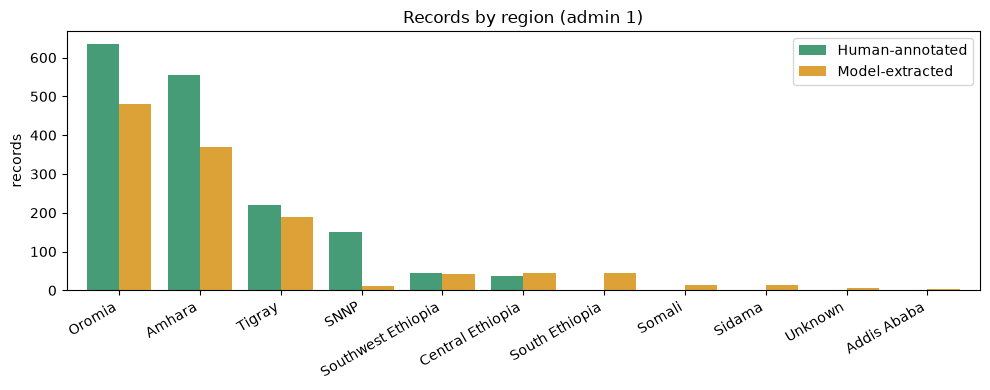

In [31]:
reg_all = pd.concat([
    gold['region'].fillna('Unknown').value_counts().rename('gold'),
    ext['region'].fillna('Unknown').value_counts().rename('extracted'),
], axis=1).fillna(0).astype(int).sort_values('gold', ascending=False)
reg_all.loc['Total'] = reg_all.sum()
display(reg_all)

ax = reg_all.drop('Total').rename(columns=dataset_labels).plot(kind='bar', figsize=(10, 4), color=[colors['gold'], colors['extracted']], width=0.8)
ax.set_ylabel('records')
ax.set_xlabel('')
ax.set_title('Records by region (admin 1)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### E5. Rows removed by each filter

In [32]:
filter_summary = pd.DataFrame(filter_log)
filter_summary['rows_removed'] = filter_summary['rows_before'] - filter_summary['rows_after']
filter_summary

,step,dataset,rows_before,rows_after,rows_removed
0,grain_yield 100-10000,extracted,1536,1463,73
1,grain_yield 100-10000,gold,1711,1709,2
2,wheat only (no-crop rows kept),extracted,1463,1400,63
3,wheat only (no-crop rows kept),gold,1709,1642,67
4,no admin and no lat/long removed,extracted,1400,1222,178
5,no admin and no lat/long removed,gold,1642,1642,0


### E6. Check `grain_yield` (no NaN, all values between 100 and 10,000)

In [33]:
for name, df in [('extracted', ext), ('gold', gold)]:
    y = df['grain_yield']
    print(f'{name}: rows {len(df)} | NaN {y.isna().sum()} | min {y.min():.0f} | max {y.max():.0f} | mean {y.mean():.0f}')
    assert y.notna().all() and y.between(100, 10000).all()
print('grain_yield check passed')

extracted: rows 1222 | NaN 0 | min 235 | max 8743 | mean 3536
gold: rows 1642 | NaN 0 | min 235 | max 9590 | mean 3430
grain_yield check passed


### E7. Rows and papers kept in each dataset

In [34]:
papers_ext = set(ext['paper_key'])
papers_gold = set(gold['paper_key'])

print('Extracted:', len(ext), 'rows from', len(papers_ext), 'papers')
print('Gold     :', len(gold), 'rows from', len(papers_gold), 'papers')
print('Papers in gold but not in extracted:', len(papers_gold - papers_ext))
print('Papers in extracted but not in gold:', len(papers_ext - papers_gold))
sorted(papers_gold - papers_ext)

Extracted: 1222 rows from 75 papers
Gold     : 1642 rows from 89 papers
Papers in gold but not in extracted: 14
Papers in extracted but not in gold: 0


['doi_10_1007_s44279_026_00692_3',
 'doi_10_1016_j_geoderma_2018_12_020',
 'doi_10_1016_j_heliyon_2020_e05629',
 'doi_10_1016_j_jafr_2025_101845',
 'doi_10_1038_s41598_025_34369_6',
 'doi_10_1080_00103624_2022_2063325',
 'doi_10_11648_j_aff_20221101_17',
 'doi_10_11648_j_be_20240801_13',
 'doi_10_1186_s12870_025_07864_1',
 'doi_10_1371_journal_pone_0335174',
 'doi_10_1515_opag_2022_0359',
 'doi_10_5539_jas_v9n7p202',
 'doi_10_5829_idosi_wasj_2013_22_04_1196',
 'file_google_scholar_126']

### E8. Usable observations
**Usable observation** = a record with a valid `grain_yield` (100-10,000 kg/ha) and known elemental `n_rate` and `p_rate` (after the conversion in D). Change `usable_cols` to redefine it. It is defined here because the map in F3 uses it.

In [35]:
usable_cols = ['n_rate', 'p_rate']

for df in (ext, gold):
    df['usable'] = df['grain_yield'].notna() & df[usable_cols].notna().all(axis=1)

summary = pd.DataFrame({
    'records': [len(ext), len(gold)],
    'usable records': [ext['usable'].sum(), gold['usable'].sum()],
    'papers': [ext['paper_key'].nunique(), gold['paper_key'].nunique()],
    'papers with usable records': [ext.loc[ext['usable'], 'paper_key'].nunique(),
                                   gold.loc[gold['usable'], 'paper_key'].nunique()],
}, index=['extracted', 'gold'])
summary

,records,usable records,papers,papers with usable records
extracted,1222,1122,75,71
gold,1642,1348,89,81


## Section F. Exploration
Correlation, N and P vs yield, map and yield distribution on the cleaned data. Correlations use only the rows where the nutrient value is available (NaN are not set to 0).

### F1. Correlation of n, p, k, s with `grain_yield` (each nutrient individually)

In [36]:
corr_rows = []
for name, df in [('extracted', ext), ('gold', gold)]:
    for c in nutrients:
        sub = df[[c, 'grain_yield']].dropna()
        corr_rows.append({'dataset': name, 'nutrient': c, 'n_rows': len(sub),
                          'pearson': round(sub.corr().iloc[0, 1], 3),
                          'spearman': round(sub.corr(method='spearman').iloc[0, 1], 3)})

corr_table = pd.DataFrame(corr_rows)
corr_table

,dataset,nutrient,n_rows,pearson,spearman
0,extracted,n_rate,1198,0.326,0.391
1,extracted,p_rate,1134,0.241,0.266
2,extracted,k_rate,472,-0.058,-0.112
3,extracted,s_rate,751,0.277,0.322
4,gold,n_rate,1552,0.310,0.309
5,gold,p_rate,1384,0.195,0.153
6,gold,k_rate,381,0.002,0.007
7,gold,s_rate,898,0.200,0.252


### F2. Graph: elemental N and P vs `grain_yield` (model-extracted and human-annotated)
Axes: `grain_yield` on the x-axis, nutrient rate on the y-axis (black line = linear fit of the nutrient on yield).

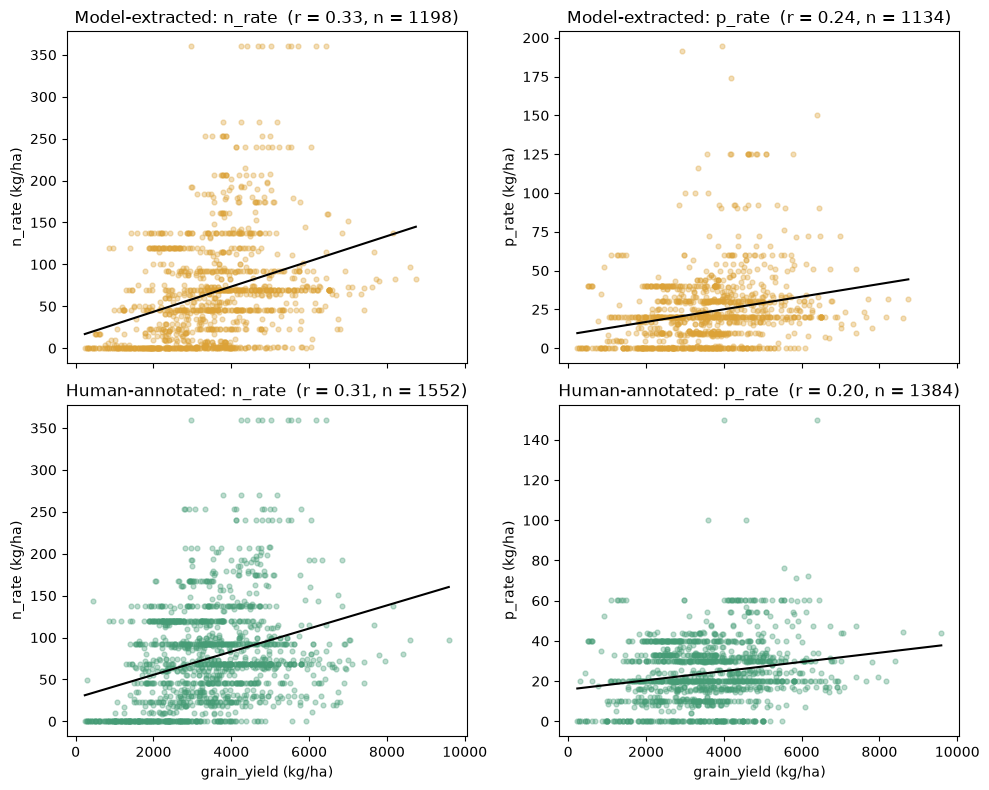

In [37]:
nutrients_plot = ['n_rate', 'p_rate']

fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True)

for i, (name, df) in enumerate([('extracted', ext), ('gold', gold)]):
    for j, c in enumerate(nutrients_plot):
        ax = axes[i, j]
        sub = df[[c, 'grain_yield']].dropna()
        ax.scatter(sub['grain_yield'], sub[c], s=12, alpha=0.35, color=colors[name])
        if len(sub) > 2 and sub['grain_yield'].std() > 0:
            slope, intercept = np.polyfit(sub['grain_yield'], sub[c], 1)
            xs = np.array([sub['grain_yield'].min(), sub['grain_yield'].max()])
            ax.plot(xs, slope * xs + intercept, color='black', linewidth=1.5)
        r = sub.corr().iloc[0, 1]
        ax.set_title(f'{dataset_labels[name]}: {c}  (r = {r:.2f}, n = {len(sub)})')
        ax.set_ylabel(c + ' (kg/ha)')
        if i == 1:
            ax.set_xlabel('grain_yield (kg/ha)')

plt.tight_layout()
plt.show()


### F3. Usable observations by region (admin 1)
Each region is filled according to its number of usable observations (E8; one common colour scale for both panels, square-root scale, light grey = no usable observation); the colour bar gives the scale. Records whose coordinates fall outside the Ethiopian boundary are excluded from the counts. Reported region names without a polygon (the former SNNP) are assigned from the coordinates of the record, for this map only.


Model-extracted: 0 records outside Ethiopia removed; 1117 usable observations on the map; 5 usable without region or coordinates
Human-annotated: 7 records outside Ethiopia removed; 1341 usable observations on the map; 0 usable without region or coordinates


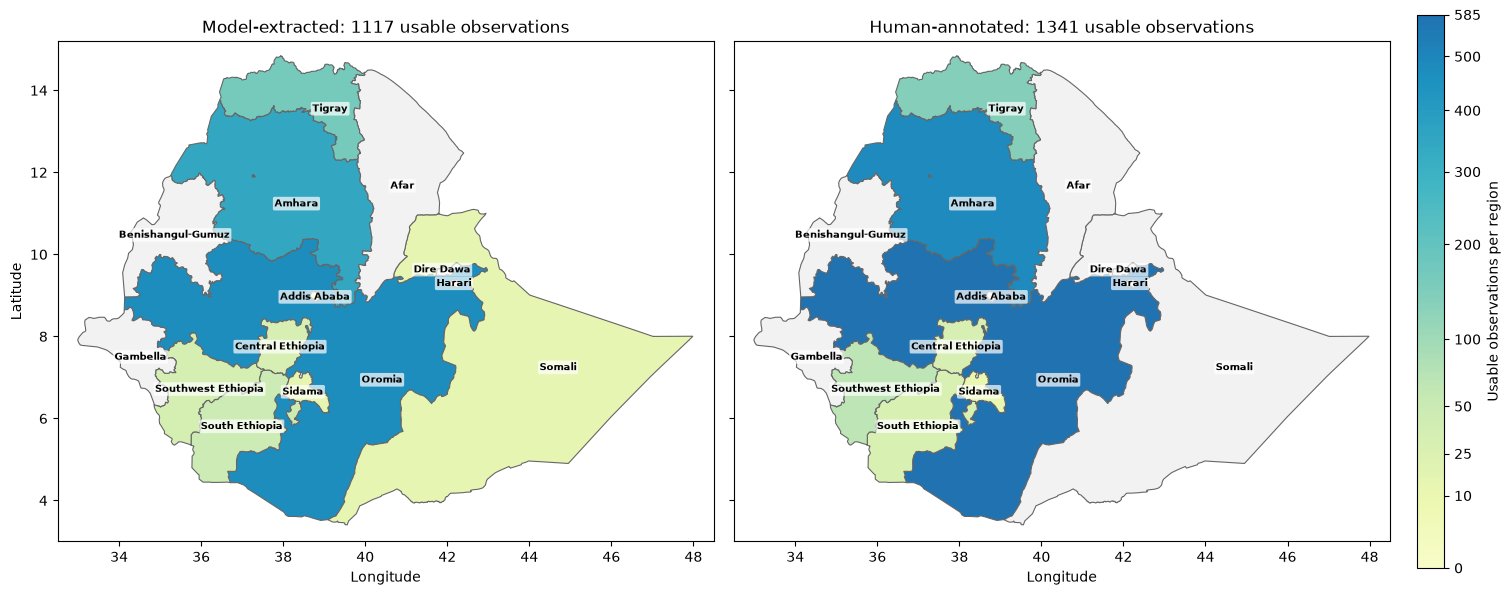

In [38]:
from shapely.geometry import Polygon
from shapely.geometry import shape, Point
from shapely.ops import unary_union
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
from matplotlib import colors as mcolors

with open(ADMIN_DIR / 'eth_regions.geojson', encoding='utf-8') as f:
    region_features = json.load(f)['features']

# region polygons and the outline of Ethiopia
region_geoms = {ft['properties']['region']: shape(ft['geometry']) for ft in region_features}
region_by_size = sorted(region_geoms, key=lambda r: region_geoms[r].area)           # small regions first
ethiopia = unary_union(list(region_geoms.values()))

def inside_ethiopia(lon, lat):
    return ethiopia.covers(Point(lon, lat))

def region_from_point(lon, lat):
    pt = Point(lon, lat)
    for name in region_by_size:
        if region_geoms[name].covers(pt):
            return name
    return None

def map_data(df):
    """Records inside Ethiopia and the number of usable observations per region polygon."""
    d = df.copy()
    has_xy = d['lat_decimal'].notna() & d['long_decimal'].notna()
    outside = pd.Series(False, index=d.index)
    outside[has_xy] = [not inside_ethiopia(lo, la) for lo, la in zip(d.loc[has_xy, 'long_decimal'], d.loc[has_xy, 'lat_decimal'])]
    d = d[~outside].copy()                                  # points outside Ethiopia are removed
    u = d.loc[d['usable']].copy()
    u['map_region'] = u['region'].fillna('Unknown')
    # reported names without a polygon (e.g. SNNP, which is split in the 2021 boundaries) or empty:
    # the region is taken from the coordinates; kept as missing if there are none
    miss = ~u['map_region'].isin(region_geoms)
    u.loc[miss, 'map_region'] = [region_from_point(lo, la) if pd.notna(lo) and pd.notna(la) else None
                                 for lo, la in zip(u.loc[miss, 'long_decimal'], u.loc[miss, 'lat_decimal'])]
    counts = u['map_region'].value_counts()
    return d, int(outside.sum()), counts, int(u['map_region'].isna().sum())

# fill colour = number of usable observations (E8) per region; one common scale for both panels
panels = []
for name, df in [('extracted', ext), ('gold', gold)]:
    panels.append((name, df) + map_data(df))
vmax = max(p[4].max() for p in panels)
base_cmap = plt.cm.YlGnBu
cmap = mcolors.LinearSegmentedColormap.from_list('YlGnBu_light', base_cmap(np.linspace(0.05, 0.7, 256)))
norm = mcolors.PowerNorm(gamma=0.5, vmin=0, vmax=vmax)     # square-root scale so that small regions stay visible
no_data_color = '#f2f2f2'

# label positions: a point inside the largest polygon of each region
region_labels = []
for ft in region_features:
    geom = ft['geometry']
    polys = [geom['coordinates']] if geom['type'] == 'Polygon' else geom['coordinates']
    biggest = max((Polygon(poly[0]) for poly in polys), key=lambda g: g.area)
    pt = biggest.representative_point()
    region_labels.append((ft['properties'].get('region', ''), pt.x, pt.y))

fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharex=True, sharey=True, layout='constrained')

for ax, (name, df, pts_df, n_out, counts, n_unassigned) in zip(axes, panels):
    # regions filled by the number of usable observations (large regions first, small ones on top)
    for reg in sorted(region_geoms, key=lambda r: -region_geoms[r].area):
        geom = region_geoms[reg]
        parts = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
        n = counts.get(reg, 0)
        fc = cmap(norm(n)) if n > 0 else no_data_color
        for part in parts:
            ax.add_patch(MplPolygon(list(part.exterior.coords), closed=True, facecolor=fc,
                                    edgecolor='0.4', linewidth=0.8))

    ax.set_title(f'{dataset_labels[name]}: {counts.sum()} usable observations')
    ax.set_xlabel('Longitude')
    ax.set_aspect('equal')
    ax.set_xlim(32.5, 48.5)
    ax.set_ylim(3, 15.2)
    # region labels
    for lab_name, lx, ly in region_labels:
        ax.text(lx, ly, lab_name, fontsize=7.5, ha='center', va='center', fontweight='bold', color='black',
                bbox=dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.7))
    print(f'{dataset_labels[name]}: {n_out} records outside Ethiopia removed; '
          f'{counts.sum()} usable observations on the map; {n_unassigned} usable without region or coordinates')
axes[0].set_ylabel('Latitude')
# colour bar: number of usable observations per region (common scale for both panels)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, ax=axes.ravel().tolist(), fraction=0.03, pad=0.02, shrink=0.8)
ticks = [t for t in (0, 10, 25, 50, 100, 200, 300, 400, 500) if t < vmax] + [int(vmax)]
cbar.set_ticks(ticks)
cbar.set_label('Usable observations per region')
plt.show()

### F4. Grain yield distribution (model-extracted vs human-annotated)
General distribution only (no split by region).

In [39]:
yield_stats = (pd.concat([ext[['grain_yield']].assign(dataset='extracted'),
                         gold[['grain_yield']].assign(dataset='gold')])
               .groupby('dataset')['grain_yield']
               .agg(['count', 'min', 'median', 'mean', 'max']).round(0))
yield_stats


,count,min,median,mean,max
dataset,,,,,
extracted,1222,235.0,3540.0,3536.0,8743.0
gold,1642,235.0,3391.0,3430.0,9590.0


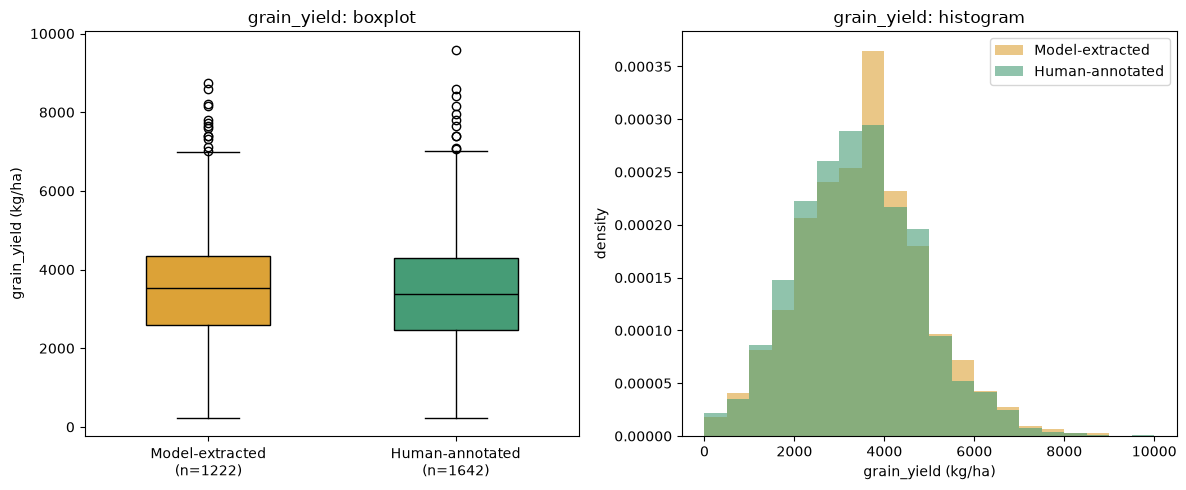

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# boxplot
bp = axes[0].boxplot([ext['grain_yield'], gold['grain_yield']], patch_artist=True, widths=0.5)
for box, name in zip(bp['boxes'], ['extracted', 'gold']):
    box.set_facecolor(colors[name])
for med in bp['medians']:
    med.set_color('black')
axes[0].set_xticks([1, 2])
axes[0].set_xticklabels([f"{dataset_labels['extracted']}\n(n={len(ext)})", f"{dataset_labels['gold']}\n(n={len(gold)})"])
axes[0].set_ylabel('grain_yield (kg/ha)')
axes[0].set_title('grain_yield: boxplot')

# histogram
bins = np.arange(0, 10001, 500)
for name, df in [('extracted', ext), ('gold', gold)]:
    axes[1].hist(df['grain_yield'], bins=bins, alpha=0.6, color=colors[name], label=dataset_labels[name], density=True)
axes[1].set_xlabel('grain_yield (kg/ha)')
axes[1].set_ylabel('density')
axes[1].set_title('grain_yield: histogram')
axes[1].legend()

plt.tight_layout()
plt.show()


## Section G. Human-annotated vs model-extracted: usable observations

### G1. Number of observations per paper (human-annotated and model-extracted)

In [41]:
per_paper = pd.DataFrame({
    'gold_records': gold.groupby('paper_key').size(),
    'extracted_records': ext.groupby('paper_key').size(),
    'gold_usable': gold.groupby('paper_key')['usable'].sum(),
    'extracted_usable': ext.groupby('paper_key')['usable'].sum(),
}).fillna(0).astype(int)
per_paper['difference_usable'] = per_paper['extracted_usable'] - per_paper['gold_usable']
per_paper = per_paper.sort_values('gold_usable', ascending=False)
print('papers:', len(per_paper))
print(per_paper[['gold_records', 'extracted_records', 'gold_usable', 'extracted_usable']].sum())
per_paper

papers: 89
gold_records         1642
extracted_records    1222
gold_usable          1348
extracted_usable     1122
dtype: int64


,gold_records,extracted_records,gold_usable,extracted_usable,difference_usable
paper_key,,,,,
doi_10_1371_journal_pone_0335174,83,0,74,0,-74
doi_10_9734_IJPSS_2015_20055,72,72,72,72,0
doi_10_11648_j_ajasr_20241003_12,54,54,54,54,0
doi_10_1016_j_geoderma_2018_12_020,49,0,49,0,-49
doi_10_3389_fagro_2025_1541332,64,64,48,64,16
doi_10_5829_idosi_wjas_2021_33_39,42,14,39,14,-25
doi_10_5539_jas_v9n7p202,40,0,37,0,-37
doi_10_1080_00103624_2020_1845361,36,12,36,0,-36
doi_10_1080_00103624_2022_2063325,32,0,32,0,-32


### G2. Usable observations by region

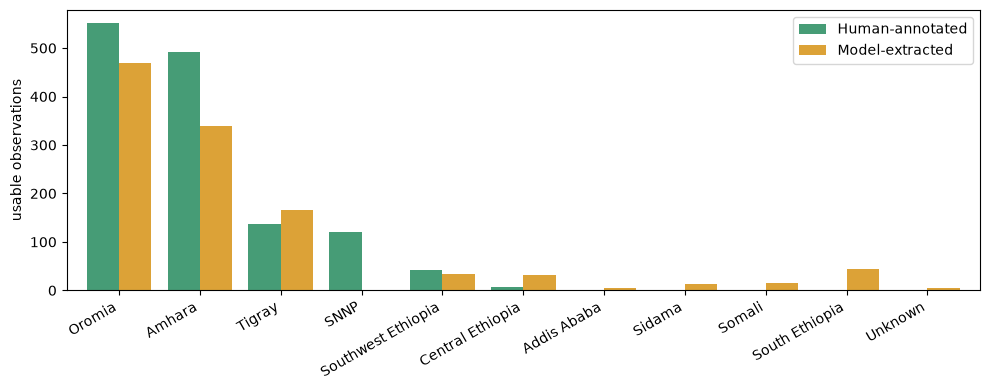

In [42]:
# by region (admin 1): graph only
reg_ext = ext[ext['usable']].assign(region=ext['region'].fillna('Unknown')).groupby('region').size().rename('extracted')
reg_gold = gold[gold['usable']].assign(region=gold['region'].fillna('Unknown')).groupby('region').size().rename('gold')
reg_tab = pd.concat([reg_gold, reg_ext], axis=1).fillna(0).astype(int).sort_values('gold', ascending=False)

ax = reg_tab.rename(columns=dataset_labels).plot(kind='bar', figsize=(10, 4), color=[colors['gold'], colors['extracted']], width=0.8)
ax.set_ylabel('usable observations')
ax.set_xlabel('')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

## Section H. Final column selection
Same columns in both datasets. Dropped: the degree/minute/second coordinates (the decimal coordinates are kept) and the fertilizer product columns (`p2o5`, `k2o`, `urea`, `dap`, `tsp`, `kcl`, `nps`, `npsb`, `npszn`, `npsznb`), which are already in `n_rate`, `p_rate`, `k_rate`, `s_rate`. Edit `final_cols` to change the selection.

In [43]:
final_cols = ['dataset', 'paper_key', 'file_name',
              'region', 'zone', 'woreda', 'site_name', 'lat_decimal', 'long_decimal', 'region_source',
              'trial_year', 'altitude', 'total_rainfall', 'mean_tmax', 'mean_tmin',
              'soil_type', 'sand_pct', 'silt_pct', 'clay_pct', 'ph', 'cec', 'soc', 'total_n',
              'crop', 'variety',
              'n_rate', 'p_rate', 'k_rate', 's_rate',
              'usable', 'grain_yield']

ext_final = ext[final_cols].copy()
gold_final = gold[final_cols].copy()

assert list(ext_final.columns) == list(gold_final.columns)
print('final columns:', len(final_cols))
print('extracted:', ext_final.shape, '| gold:', gold_final.shape)

final columns: 31
extracted: (1222, 31) | gold: (1642, 31)


In [44]:
# NA count of the final columns
pd.concat([ext_final.isna().sum().rename('extracted NA'),
           gold_final.isna().sum().rename('gold NA')], axis=1)

,extracted NA,gold NA
dataset,0,0
paper_key,0,0
file_name,433,0
region,5,0
zone,0,0
woreda,0,0
site_name,387,582
lat_decimal,128,86
long_decimal,122,71
region_source,5,0


In [45]:
print(ext_final.columns)

Index(['dataset', 'paper_key', 'file_name', 'region', 'zone', 'woreda', 'site_name', 'lat_decimal', 'long_decimal', 'region_source', 'trial_year', 'altitude', 'total_rainfall', 'mean_tmax',
       'mean_tmin', 'soil_type', 'sand_pct', 'silt_pct', 'clay_pct', 'ph', 'cec', 'soc', 'total_n', 'crop', 'variety', 'n_rate', 'p_rate', 'k_rate', 's_rate', 'usable', 'grain_yield'],
      dtype='str')


In [46]:
ext_final.to_csv(BASE / 'extracted_final.csv', index=False)
gold_final.to_csv(BASE / 'gold_final.csv', index=False)